(736, 1052, 3)


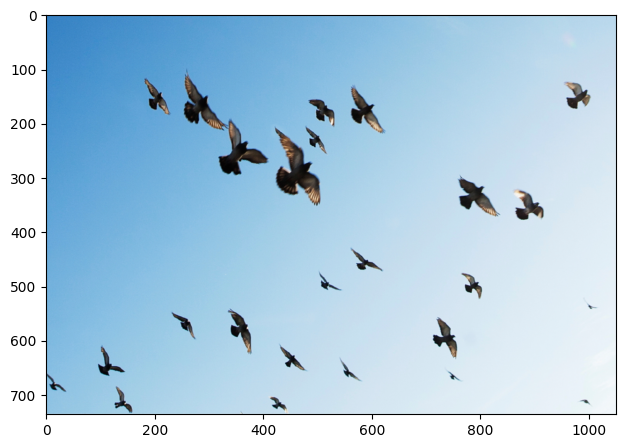

In [12]:
import cv2 
import matplotlib.pyplot as plt 
bgr = cv2.imread('birds.png')
b,g,r = cv2.split(bgr) 
rgb = cv2.merge([r,g,b])
print(rgb.shape)
plt.figure(figsize = (rgb.shape[0]/100,rgb.shape[1]/100),dpi = 100)
plt.imshow(rgb)
plt.show()

# pooling 

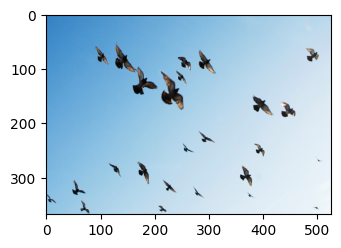

In [13]:
subrgb = rgb[::2,::2,:]
subrgb1 = rgb[0::2,0::2,:]


plt.figure(figsize = (subrgb.shape[0]/100,subrgb.shape[1]/100),dpi = 100)
plt.imshow(subrgb)
plt.show()

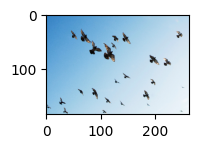

In [14]:
subrgb2 = rgb[::4,::4,:]
subrgb2 = subrgb[0::2,0::2,:]


plt.figure(figsize = (subrgb2.shape[0]/100,subrgb2.shape[1]/100),dpi = 100)
plt.imshow(subrgb2)
plt.show()

(623, 623, 3)


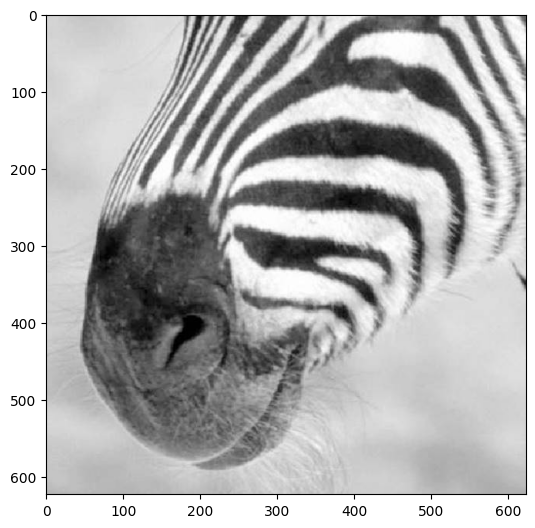

In [17]:
import cv2 
import matplotlib.pyplot as plt 
bgr = cv2.imread('zebra512.jpg')

b,g,r = cv2.split(bgr) 
rgb = cv2.merge([r,g,b])
print(rgb.shape)
plt.figure(figsize = (rgb.shape[0]/100,rgb.shape[1]/100),dpi = 100)
plt.imshow(rgb)
plt.show()

[[0.00088806]
 [0.00158611]
 [0.00272177]
 [0.00448744]
 [0.00710844]
 [0.01081877]
 [0.01582012]
 [0.02222644]
 [0.03000255]
 [0.03891121]
 [0.04848635]
 [0.0580487 ]
 [0.0667719 ]
 [0.07379436]
 [0.07835755]
 [0.07994048]
 [0.07835755]
 [0.07379436]
 [0.0667719 ]
 [0.0580487 ]
 [0.04848635]
 [0.03891121]
 [0.03000255]
 [0.02222644]
 [0.01582012]
 [0.01081877]
 [0.00710844]
 [0.00448744]
 [0.00272177]
 [0.00158611]
 [0.00088806]] (31, 1)
[[0.00088806 0.00158611 0.00272177 0.00448744 0.00710844 0.01081877
  0.01582012 0.02222644 0.03000255 0.03891121 0.04848635 0.0580487
  0.0667719  0.07379436 0.07835755 0.07994048 0.07835755 0.07379436
  0.0667719  0.0580487  0.04848635 0.03891121 0.03000255 0.02222644
  0.01582012 0.01081877 0.00710844 0.00448744 0.00272177 0.00158611
  0.00088806]]
(31, 31) [[7.88647920e-07 1.40855549e-06 2.41709089e-06 3.98510917e-06
  6.31270776e-06 9.60769852e-06 1.40491895e-05 1.97383749e-05
  2.66440192e-05 3.45554302e-05 4.30587174e-05 5.15506442e-05
  5.9297

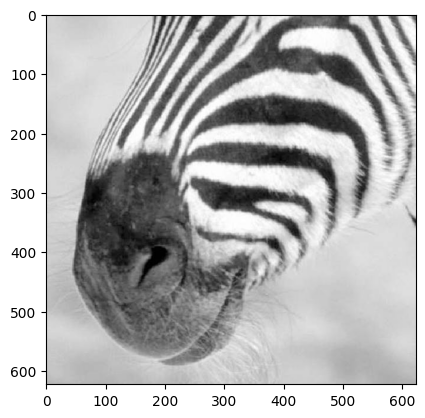

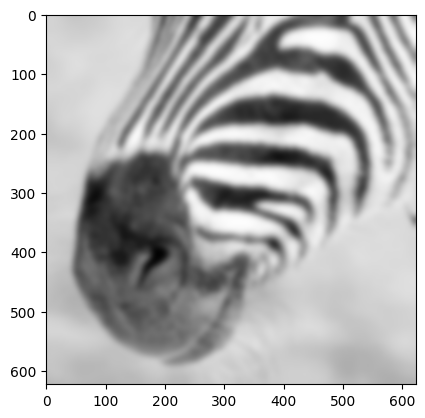

In [29]:
import numpy as np 
ksize = 7
#sigma = (ksize-1)/2*0.3+0.8
kernel = cv2.getGaussianKernel(ksize = 31, sigma =0, ktype=cv2.CV_64F)
print(kernel,kernel.shape)

print(kernel.T)
kernel2d = kernel @ kernel.T 
print(kernel2d.shape,kernel2d)

print(np.sum(kernel2d))

gaussed_rgb = cv2.filter2D(rgb,ddepth =-1,kernel = kernel2d)
plt.imshow(rgb)
plt.show()
plt.imshow(gaussed_rgb)
plt.show()

# prove gaussian blur is low pass filter 

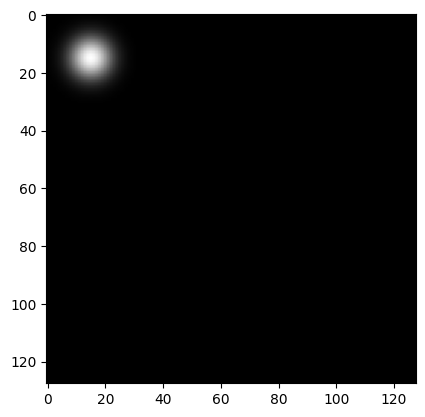

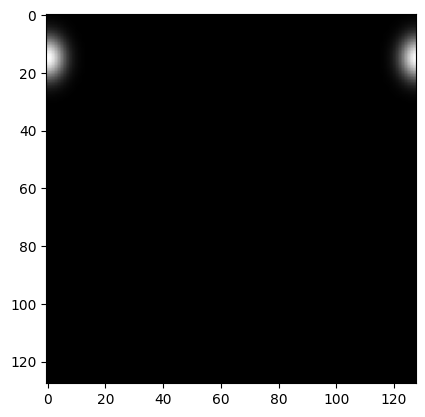

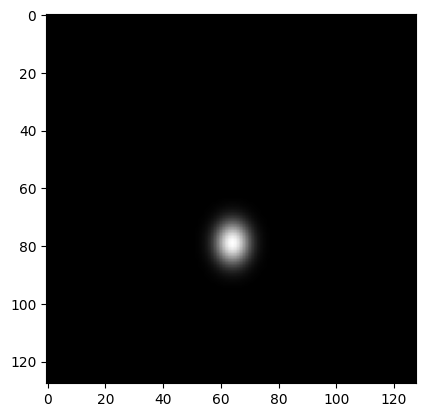

In [51]:
import numpy as np 

kernel = cv2.getGaussianKernel(ksize = 31, sigma =0, ktype=cv2.CV_64F)
#print(kernel,kernel.shape)

#print(kernel.T)
kernel2d = kernel @ kernel.T 
#print(kernel2d.shape,kernel2d)



pad_kernel = np.zeros((128,128))
pad_kernel[:kernel2d.shape[0],:kernel2d.shape[1]] = kernel2d[:,:]
#print(pad_kernel)
plt.imshow(pad_kernel,cmap='gray')
plt.show()




pad_kernel_fft = np.fft.fft(pad_kernel)
pad_kernel_fft_shift = np.fft.fftshift(pad_kernel_fft)
plt.imshow(np.log(np.abs(pad_kernel_fft)+1),cmap = 'gray')
plt.show()

plt.imshow(np.log(np.abs(pad_kernel_fft_shift)+1),cmap='gray')
plt.show()


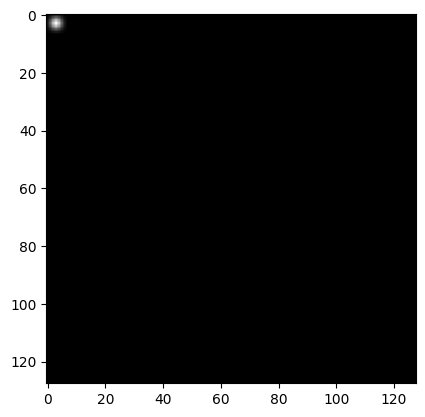

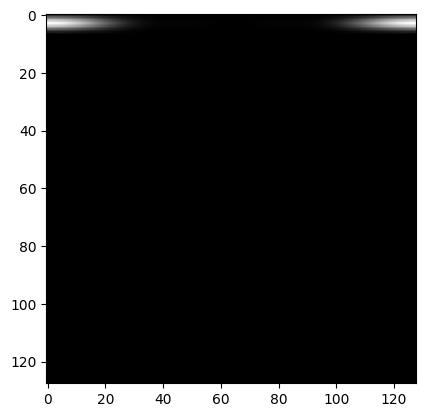

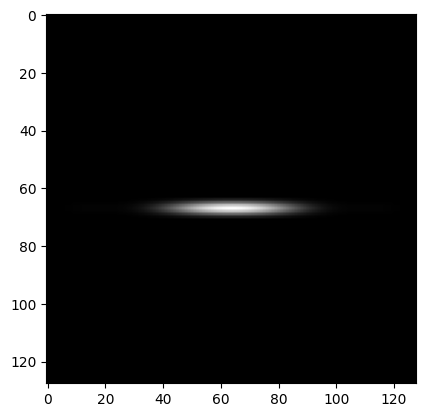

In [52]:
import numpy as np 

kernel = cv2.getGaussianKernel(ksize = 7, sigma =0, ktype=cv2.CV_64F)
#print(kernel,kernel.shape)

#print(kernel.T)
kernel2d = kernel @ kernel.T 
#print(kernel2d.shape,kernel2d)



pad_kernel = np.zeros((128,128))
pad_kernel[:kernel2d.shape[0],:kernel2d.shape[1]] = kernel2d[:,:]
#print(pad_kernel)
plt.imshow(pad_kernel,cmap='gray')
plt.show()




pad_kernel_fft = np.fft.fft(pad_kernel)
pad_kernel_fft_shift = np.fft.fftshift(pad_kernel_fft)
plt.imshow(np.log(np.abs(pad_kernel_fft)+1),cmap = 'gray')
plt.show()

plt.imshow(np.log(np.abs(pad_kernel_fft_shift)+1),cmap='gray')
plt.show()


# upsampling 

(623, 623, 3)


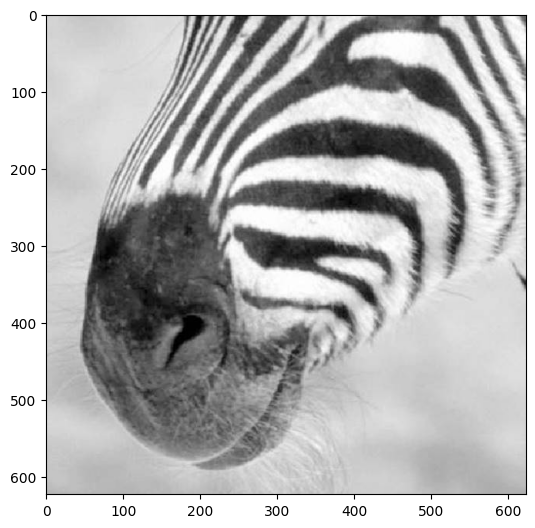

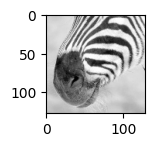

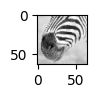

(64, 64, 3)


In [8]:
import cv2 
import matplotlib.pyplot as plt 
bgr = cv2.imread('zebra512.jpg')


b,g,r = cv2.split(bgr) 
rgb = cv2.merge([r,g,b])
print(rgb.shape)
plt.figure(figsize = (rgb.shape[0]/100,rgb.shape[1]/100),dpi = 100)
plt.imshow(rgb)
plt.show()


rgb_128= cv2.resize(rgb,(128,128))
plt.figure(figsize = (rgb_128.shape[0]/100,rgb_128.shape[1]/100),dpi = 100)
plt.imshow(rgb_128)
plt.show()

rgb_64= cv2.resize(rgb,(64,64))
plt.figure(figsize =( (rgb_64.shape[0]/100,rgb_64.shape[1]/100)),dpi = 100)
plt.imshow(rgb_64)
plt.show()
print(rgb_64.shape)


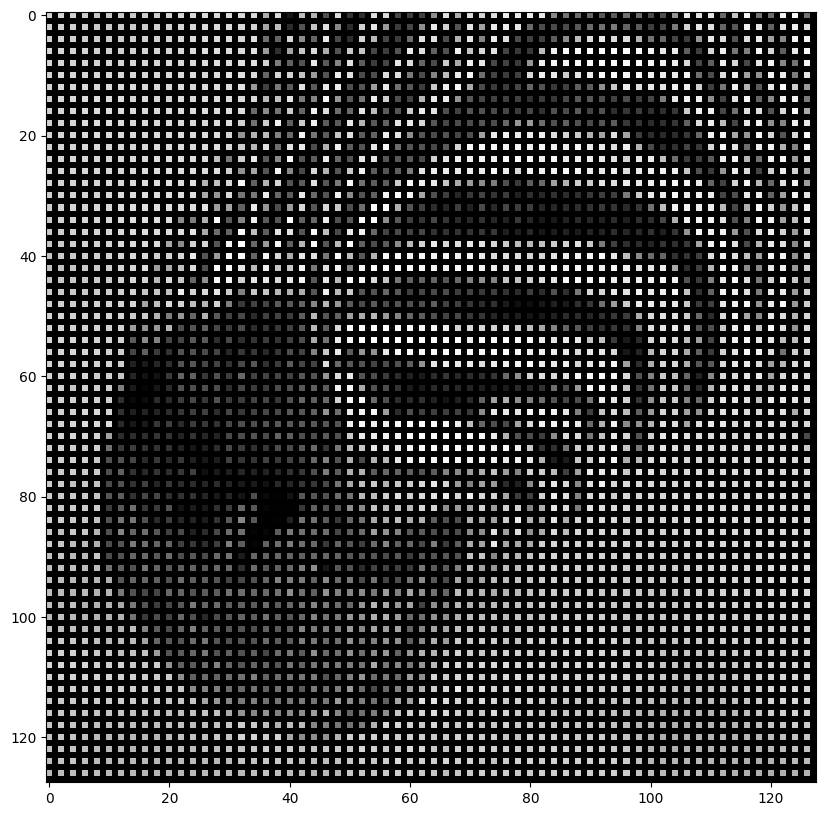

In [14]:
import numpy as np
upsampling_128 = np.zeros((128,128,3))
upsampling_128[::2,::2,:] = rgb_64[:,:,:]
plt.figure(figsize = (10,10),dpi = 100)
plt.imshow(upsampling_128/255)
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.242156862745098].


[[0.25 0.5  0.25]
 [0.5  1.   0.5 ]
 [0.25 0.5  0.5 ]]


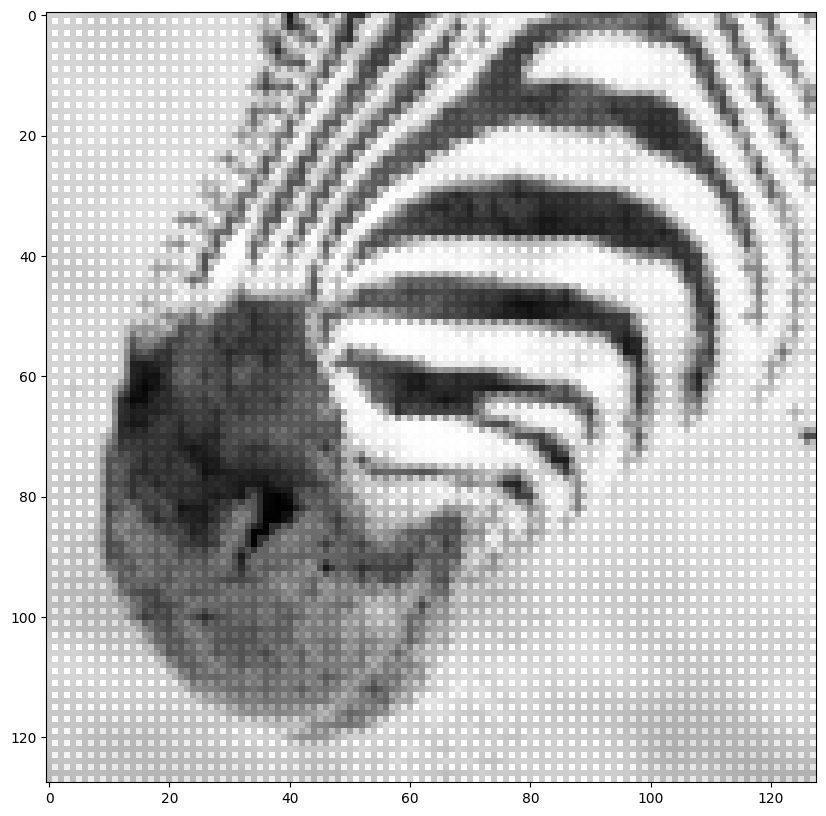

In [16]:
up_filter = np.array([[0.25,0.5,0.25],[0.5,1,0.5],[0.25,0.5,0.5]])
print(up_filter)
upsampling_rebalanced_128 = cv2.filter2D(upsampling_128,ddepth = -1, kernel = up_filter)
plt.figure(figsize =(10,10),dpi = 100)
plt.imshow(upsampling_rebalanced_128/255)
plt.show()